- Business problem:
An e-commerce company struggles to predict how much demand there will be for its products.

- Objective: An e-commerce platform aimed to predict customer demand to optimize pricing and inventory management.

- Approach: Time series data of customer browsing behavior, product views, and historical sales are collected. Multiple models were used to capture seasonality and long-term dependencies.

- Outcome: Accurate demand forecasts helped the e-commerce platform optimize pricing, improve product recommendations, and efficiently manage inventory, resulting in increased sales and customer retention.

In [1]:
import pandas as pd

In [ ]:
df = pd.read_csv(r'data/demand.csv')
df.head()   

,record_ID,week,store_id,sku_id,total_price,base_price,is_featured_sku,is_display_sku,units_sold
0,1,17/01/11,8091,216418,99.0375,111.8625,0,0,20
1,2,17/01/11,8091,216419,99.0375,99.0375,0,0,28
2,3,17/01/11,8091,216425,133.9500,133.9500,0,0,19
3,4,17/01/11,8091,216233,133.9500,133.9500,0,0,44
4,5,17/01/11,8091,217390,141.0750,141.0750,0,0,52


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150150 entries, 0 to 150149
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   record_ID        150150 non-null  int64  
 1   week             150150 non-null  object 
 2   store_id         150150 non-null  int64  
 3   sku_id           150150 non-null  int64  
 4   total_price      150149 non-null  float64
 5   base_price       150150 non-null  float64
 6   is_featured_sku  150150 non-null  int64  
 7   is_display_sku   150150 non-null  int64  
 8   units_sold       150150 non-null  int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 10.3+ MB


In [6]:
df.describe()

,record_ID,store_id,sku_id,total_price,base_price,is_featured_sku,is_display_sku,units_sold
count,150150.000000,150150.000000,150150.000000,150149.000000,150150.000000,150150.000000,150150.000000,150150.000000
mean,106271.555504,9199.422511,254761.132468,206.626751,219.425927,0.095611,0.133200,51.674206
std,61386.037861,615.591445,85547.306447,103.308516,110.961712,0.294058,0.339792,60.207904
min,1.000000,8023.000000,216233.000000,41.325000,61.275000,0.000000,0.000000,1.000000
25%,53111.250000,8562.000000,217217.000000,130.387500,133.237500,0.000000,0.000000,20.000000
50%,106226.500000,9371.000000,222087.000000,198.075000,205.912500,0.000000,0.000000,35.000000
75%,159452.750000,9731.000000,245338.000000,233.700000,234.412500,0.000000,0.000000,62.000000
max,212644.000000,9984.000000,679023.000000,562.162500,562.162500,1.000000,1.000000,2876.000000


This dataset contains 150150 records in which 51 units sold on an avg. As per the statistics, max to max 2879 units sold on record and minimum 1 unit sold too. This shows how much difference is !!

In [7]:
missing_values = df.isnull().sum()
missing_values

record_ID          0
week               0
store_id           0
sku_id             0
total_price        1
base_price         0
is_featured_sku    0
is_display_sku     0
units_sold         0
dtype: int64

In [3]:
# Missing value
# Calculate median value by grouping to skuid
median_value_per_skuid = df.groupby('sku_id')['total_price'].median()
#print(median_value_per_skuid.value_counts())
# fill the missing values and check it
df['total_price'].fillna(df['sku_id'].map(median_value_per_skuid), inplace=True)

df.isnull().sum()

C:\Users\Asus\AppData\Local\Temp\ipykernel_12724\3585646993.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['total_price'].fillna(df['sku_id'].map(median_value_per_skuid), inplace=True)


record_ID          0
week               0
store_id           0
sku_id             0
total_price        0
base_price         0
is_featured_sku    0
is_display_sku     0
units_sold         0
dtype: int64

In [6]:
## Convert date column into datetime format

df['week'] = pd.to_datetime(df['week'], format='%d/%m/%y')

## Aggregate the data by week and sum its units sold
weekly_data = df.groupby('week')['units_sold'].sum().reset_index()
weekly_data.head(10)

,week,units_sold
0,2011-01-17,60029
1,2011-01-24,56752
2,2011-01-31,51467
3,2011-02-07,54656
4,2011-02-14,109207
5,2011-02-21,82986
6,2011-02-28,84153
7,2011-03-07,56231
8,2011-03-14,53376
9,2011-03-21,61539


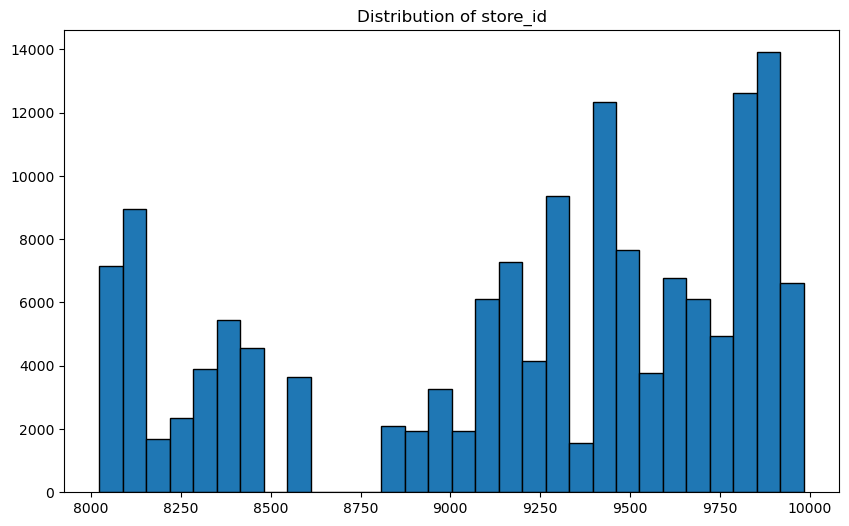

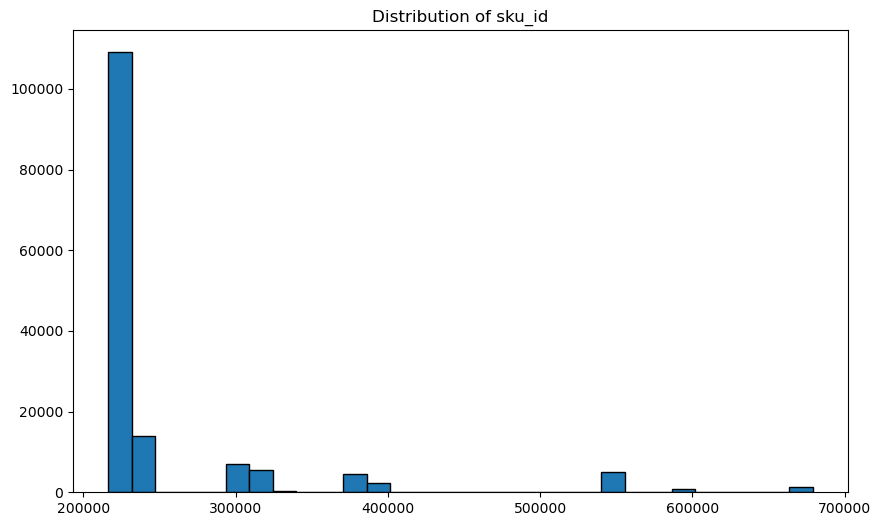

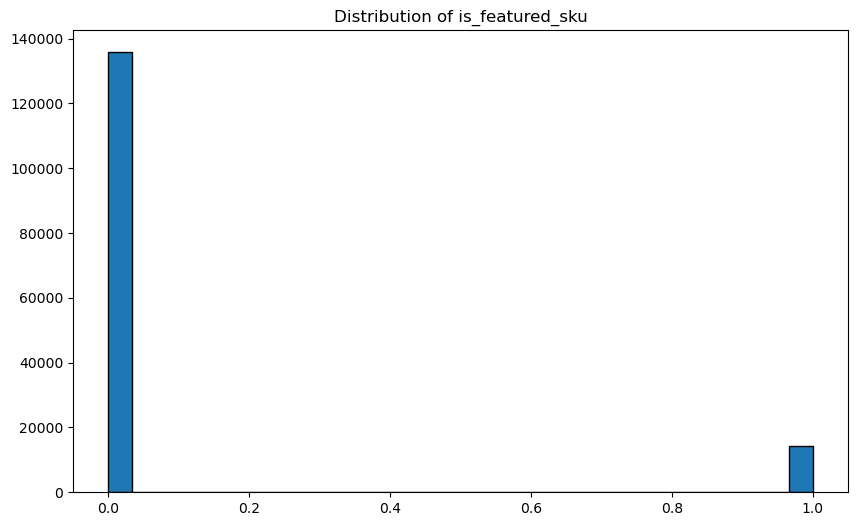

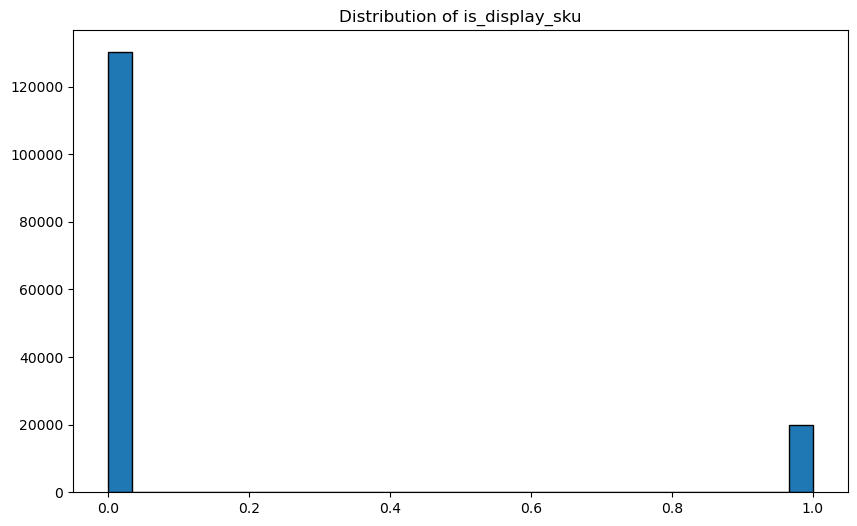

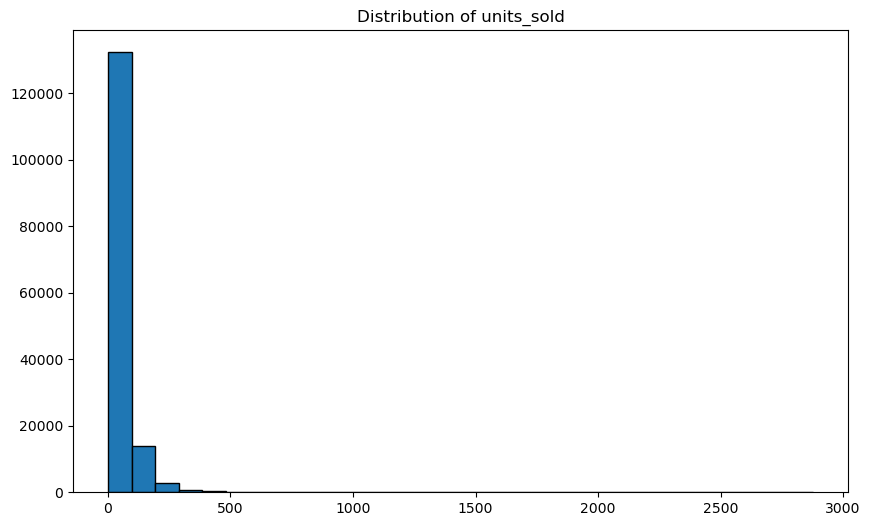

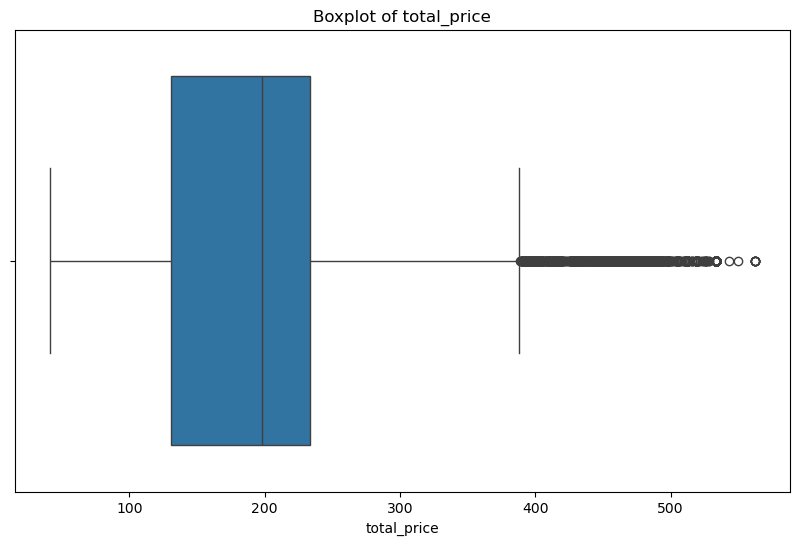

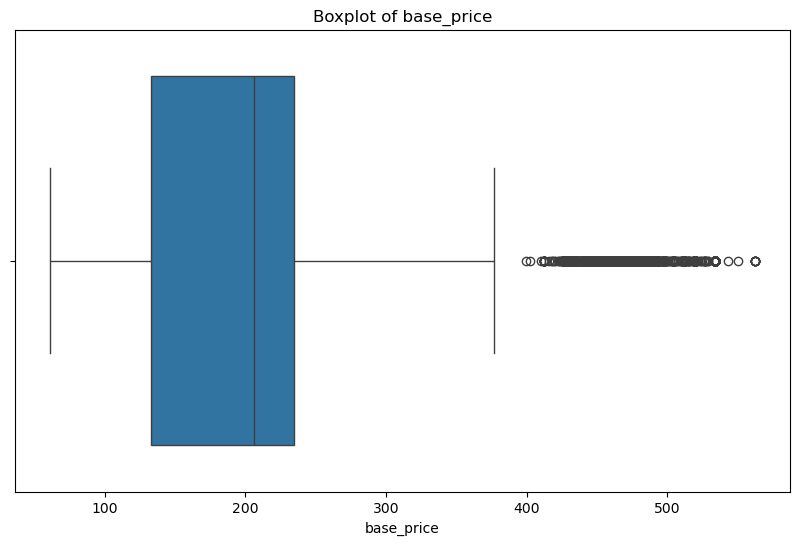

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

#plot histogram of categorical features
categorical_features = ['store_id', 'sku_id', 'is_featured_sku', 'is_display_sku', 'units_sold']

for feature in categorical_features:
    plt.figure(figsize=(10, 6))
    plt.hist(df[feature], bins = 30, edgecolor='black')
    plt.title(f'Distribution of {feature}')
    plt.show()

numerical_features = ['total_price', 'base_price']

for feature in numerical_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Boxplot of {feature}')
    plt.show()

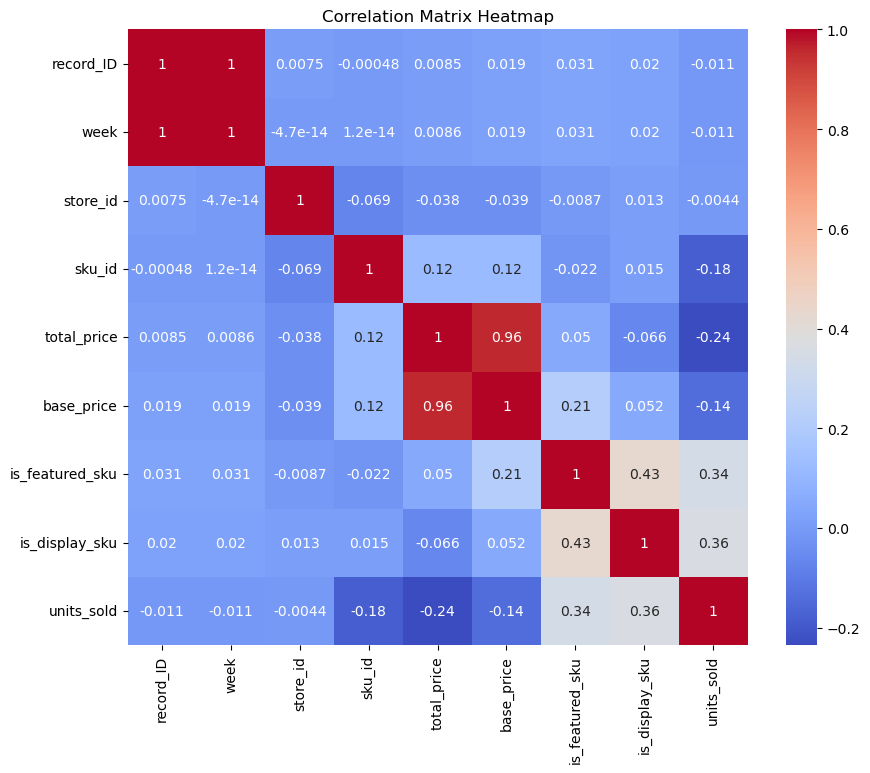

In [8]:
correlation = df.corr()

# Plot a heatmap of the correlation matrix
plt.figure(figsize=(10,8))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix Heatmap')
plt.show()


Base price and total price is highly correlated as total_price = units_sold*base_price.
is_feature_sku is somewhat correlated to is_display_sku as is_feature_sku means is product is promted or not and is_display means displayed on store or not so they are pretty much related.
Then both is_feature_sku and is_display_sku is correlated to units_sold as they affect in promoting sales.

Here are some observations based on the distribution of data and the correlation matrix:

store_id: The distribution shows that the dataset contains data from multiple stores. However, we don't have enough details to make more specific observations about the stores.

sku_id: The distribution suggests that the dataset contains data on multiple SKUs. Similarly, we can't make more specific observations without additional details.

is_featured_sku and is_display_sku: These are binary variables indicating whether the SKU was featured or displayed. The majority of SKUs were neither featured nor displayed.

units_sold: This variable, representing the number of units sold, shows a right-skewed distribution. Most of the values are low, but there are some weeks where a large number of units were sold.

total_price and base_price: These variables represent the total price and base price of the SKUs. There are some outliers, particularly for total price, which may be due to special sales or particularly expensive SKUs.

Looking at the correlation matrix, we see that is_featured_sku and is_display_sku have a moderate positive correlation with units_sold, indicating that when SKUs are featured or displayed, more units tend to be sold. There is also a slight negative correlation between total_price and units_sold, suggesting that lower priced items may sell in higher quantities.



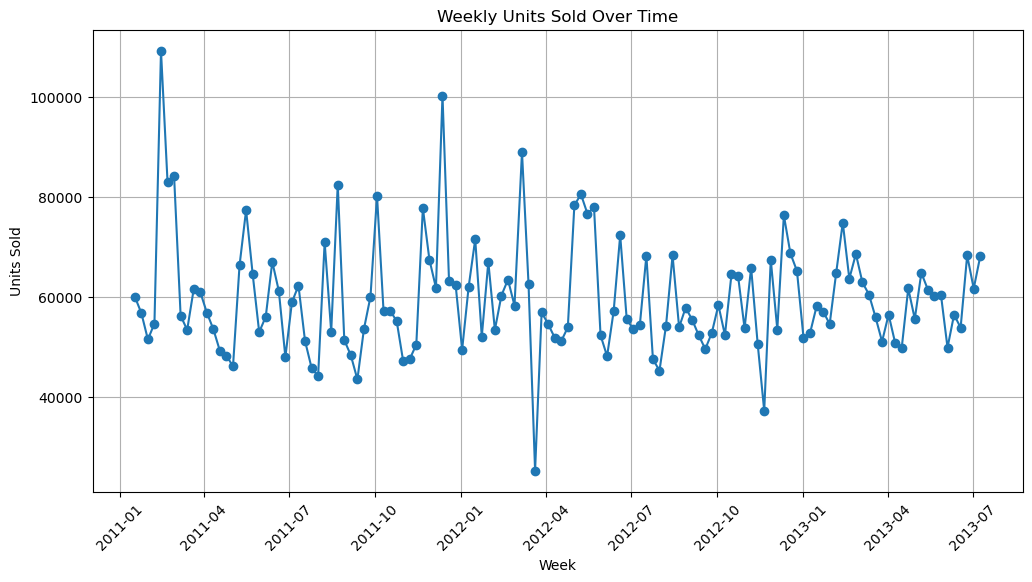

In [7]:
## Plot the time series of units sold over time
plt.figure(figsize=(12, 6))
plt.plot(weekly_data['week'], weekly_data['units_sold'], marker='o')
plt.title('Weekly Units Sold Over Time')
plt.xlabel('Week')
plt.ylabel('Units Sold')
plt.xticks(rotation=45)
plt.grid()
plt.show()

The time series plot of units_sold shows a fairly irregular pattern with some apparent seasonality. We can see periodic spikes, which could be related to specific events or seasons throughout the year. However, there is no clear increasing or decreasing trend over the entire time period.

Next, let's decompose the time series to more formally check for seasonality and trend. This involves breaking down the time series into three components:

- Trend: The underlying pattern in the data.
- Seasonality: Cyclical patterns in the data.
- Residual: The remainder of the time series after the trend and seasonal components have been removed.

We'll use the seasonal_decompose function from the statsmodels library to do this. Let's proceed with that.

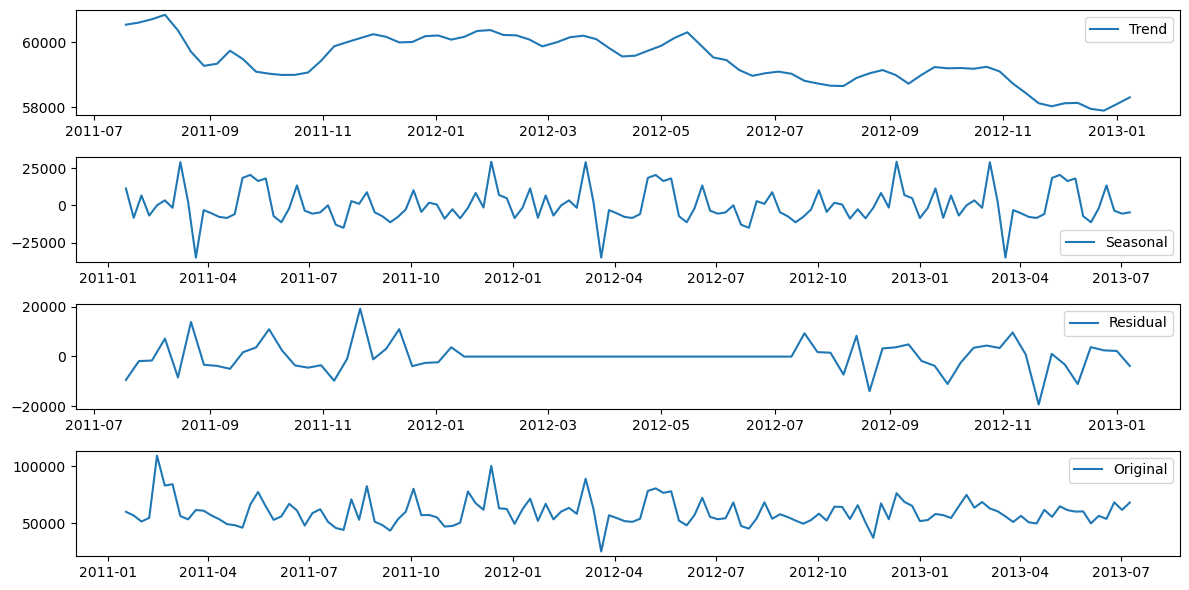

In [11]:
from statsmodels.tsa.seasonal import seasonal_decompose

#weekly_data.set_index('week', inplace = True)

plt.figure(figsize=(12, 6))

decompose = seasonal_decompose(weekly_data['units_sold'], period=52)

plt.subplot(411)
plt.plot(decompose.trend, label='Trend')
plt.legend(loc='best')

plt.subplot(412)
plt.plot(decompose.seasonal, label='Seasonal')
plt.legend(loc='best')

plt.subplot(413)
plt.plot(decompose.resid, label='Residual')
plt.legend(loc='best')

plt.subplot(414)
plt.plot(weekly_data['units_sold'], label='Original')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

The time series decomposition reveals the following insights:

Trend: The trend component shows a relatively stable pattern over time, indicating that there is no significant long-term increase or decrease in the total number of units sold.

Seasonality: The seasonality component shows a clear pattern that repeats annually. This suggests that there are specific times during the year when sales tend to be higher or lower.

Residuals: The residuals component represents the remainder of the time series after the trend and seasonal components have been removed. It shows irregular fluctuations, which could be due to random variations or other factors not captured by the trend and seasonality.

Next, we'll check for volatility in the time series. Volatility refers to the variation of price of a financial instrument over time. Here, we can consider it as the variation in the number of units sold over time. We can measure this by looking at the standard deviation of the percentage change in units_sold from one week to the next. Let's calculate this next.

After that, we'll calculate the moving average for the time series. The moving average is a commonly used technique in time series analysis to smooth out short-term fluctuations and highlight longer-term trends or cycles. We'll calculate the 4-week and 52-week (approximately one month and one year) moving averages.

In [15]:
## Calculate the percentage of units sold from one week to another week
weekly_data['units_sold_pct_change'] = weekly_data['units_sold'].pct_change()
#print(weekly_data.head(10))

# Volatility of units sold over time-> increase in volatility indicates that the demand is becoming more unpredictable, which can make it harder to forecast future demand accurately. Conversely, a decrease in volatility suggests that the demand is stabilizing, which can make forecasting easier.
volatility = weekly_data['units_sold_pct_change'].std()
volatility

0.2605985501452376

The standard deviation of the percentage change in units_sold from one week to the next is approximately 0.26. This means there is a fair amount of volatility or fluctuation in weekly sales, as the number of units sold can vary by about 26% from one week to the next.


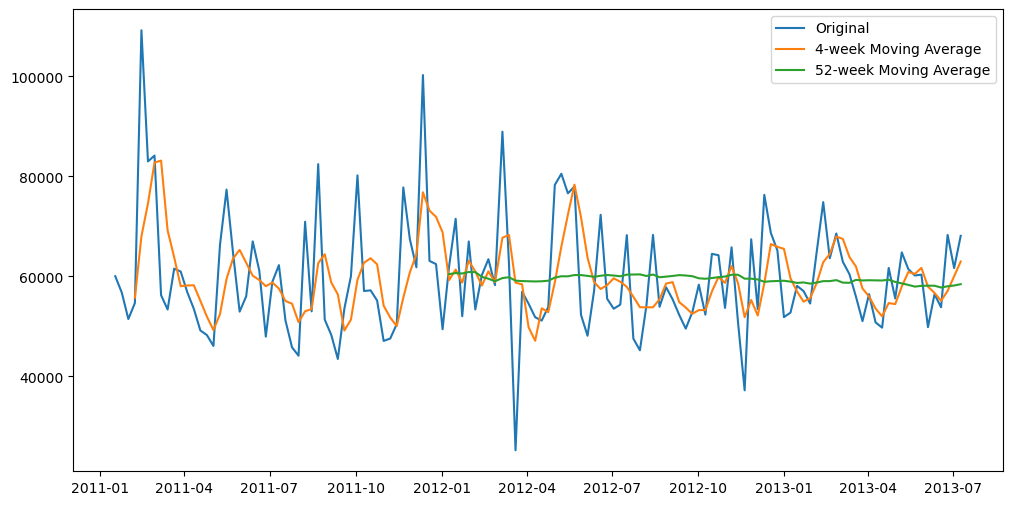

In [17]:
# Calculate the 4-weeks and 52-weeks rolling mean of units_sold
weekly_data['4-week-MA'] = weekly_data['units_sold'].rolling(window=4).mean()
weekly_data['52-week-MA'] = weekly_data['units_sold'].rolling(window=52).mean()

plt.figure(figsize=(12, 6))
plt.plot(weekly_data['units_sold'], label = 'Original')
plt.plot(weekly_data['4-week-MA'], label = '4-week Moving Average')
plt.plot(weekly_data['52-week-MA'], label = '52-week Moving Average')
plt.legend(loc='best')
plt.show()

To summarize:

Data Inspection and Cleaning: The dataset contained one missing value in the total_price column, which we filled using the median total price for the corresponding SKU.

Exploratory Data Analysis: The dataset contains sales data from multiple stores and for multiple SKUs. Most of the SKUs were neither featured nor displayed. There is a moderate positive correlation between is_featured_sku and is_display_sku and units_sold, indicating that when SKUs are featured or displayed, more units tend to be sold. There is a slight negative correlation between total_price and units_sold, suggesting that lower priced items may sell in higher quantities.

Time Series Analysis: The time series of units_sold shows an irregular pattern with some apparent seasonality, but no clear increasing or decreasing trend. The decomposition of the time series revealed a stable trend component and a clear seasonal pattern that repeats annually. The residuals show irregular fluctuations, which could be due to random variations or other factors not captured by the trend and seasonality. The volatility analysis showed that the number of units sold can vary by about 26% from one week to the next. The 4-week and 52-week moving averages provided a smoothed view of the time series.


let's first visually check the autocorrelation plot to confirm the presence of seasonality. This plot can provide a qualitative indication of the presence and type of seasonality.

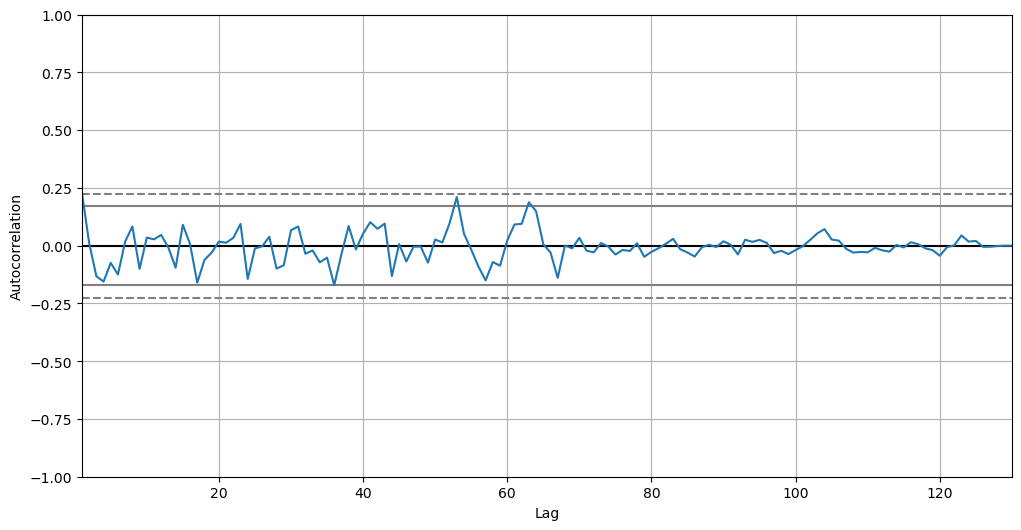

In [18]:
from pandas.plotting import autocorrelation_plot

plt.figure(figsize=(12, 6))
autocorrelation_plot(weekly_data['units_sold'])
plt.show()

The autocorrelation plot confirms the presence of seasonality in the data. We can see a sinusoidal pattern, which indicates a repeating pattern at regular intervals (seasonality).

Now let's fit a Holt-Winters seasonal model to our data. Since the amplitude of the seasonal variation doesn't increase over time, we'll use the additive version of the Holt-Winters' method. We'll train the model on the first 80% of the data and then test it on the remaining 20%. We can then evaluate the accuracy of the model's forecasts.

In [19]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

train_data = weekly_data['units_sold'][:int(0.8*len(weekly_data))]
test_data = weekly_data['units_sold'][int(0.8*len(weekly_data)):]

# fit the Holt-Winters model
hwmodel = ExponentialSmoothing(train_data, seasonal='add', seasonal_periods=52).fit()

c:\Users\Asus\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\Asus\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


In [23]:

# Resample data to weekly frequency
weekly_data_resampled = weekly_data['units_sold'].resample('W').sum()

# Split into train and test
split = int(0.8 * len(weekly_data_resampled))

train_data_resampled = weekly_data_resampled[:split]
test_data_resampled = weekly_data_resampled[split:]

# Fit the Holt-Winters model
hwmodel_resampled = ExponentialSmoothing(
    train_data_resampled,
    seasonal='add',
    seasonal_periods=52
).fit()

# Predict the test data
prediction_resampled = hwmodel_resampled.predict(
    start=test_data_resampled.index[0],
    end=test_data_resampled.index[-1]
)

# Calculate RMSE
from sklearn.metrics import mean_squared_error
from math import sqrt

rmse = sqrt(mean_squared_error(
    test_data_resampled,
    prediction_resampled
))

print("RMSE:", rmse)


RMSE: 13387.603026274608


c:\Users\Asus\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


The root mean squared error (RMSE) of the model's predictions on the test data is approximately 13387. This metric provides a measure of the accuracy of the model's forecasts.

Let's visualize the original time series along with the forecasted values to get a better understanding of the model's performance.

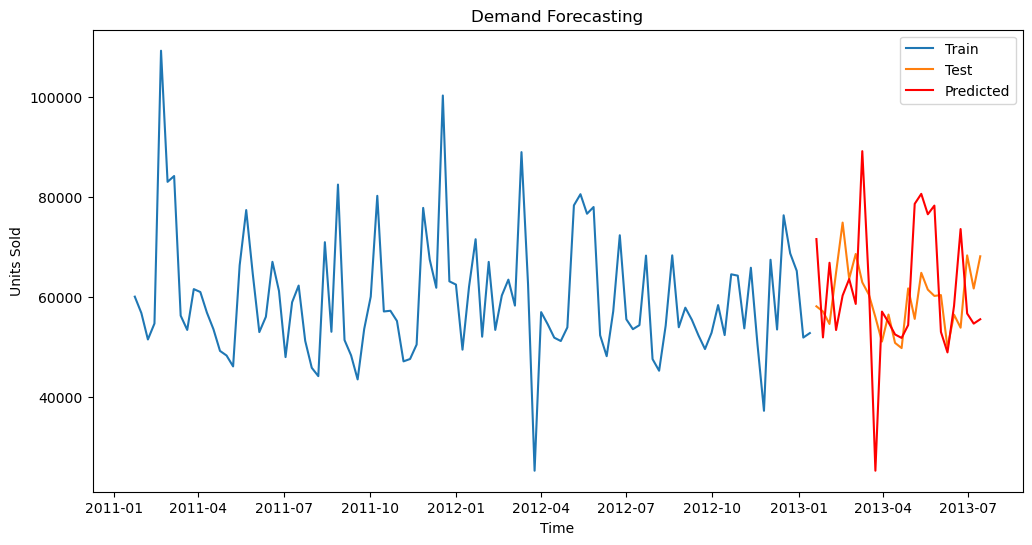

In [24]:
# plotting the actual vs predicted values
plt.figure(figsize=(12, 6))

plt.plot(train_data_resampled, label='Train')
plt.plot(test_data_resampled, label='Test')
plt.plot(prediction_resampled, label='Predicted', color='red')
plt.legend()
plt.title('Demand Forecasting')
plt.xlabel('Time')
plt.ylabel('Units Sold')
plt.show()

The plot above shows the original time series (divided into training and test sets) along with the forecasted values from the Holt-Winters' model.

The forecasted values generally follow the pattern of the original time series, indicating that the model is able to capture the seasonality in the data. However, the forecast seems to underestimate the peaks in the original series, which is consistent with the relatively high RMSE value.

It's worth noting that time series forecasting can be a complex task and the accuracy of the forecasts can depend on many factors, such as the nature of the trend and seasonality in the data, the presence of outliers, and the choice of model and its parameters. There might be room for improving the model's performance by trying different models, tuning the model's parameters, or preprocessing the data in different ways.

c:\Users\Asus\anaconda3\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
10:18:45 - cmdstanpy - INFO - Chain [1] start processing
10:18:45 - cmdstanpy - INFO - Chain [1] done processing


Holt-Winters RMSE: 13387.603026274608
ARIMA RMSE: 6235.736166484375
Prophet RMSE: 7717.694626470364


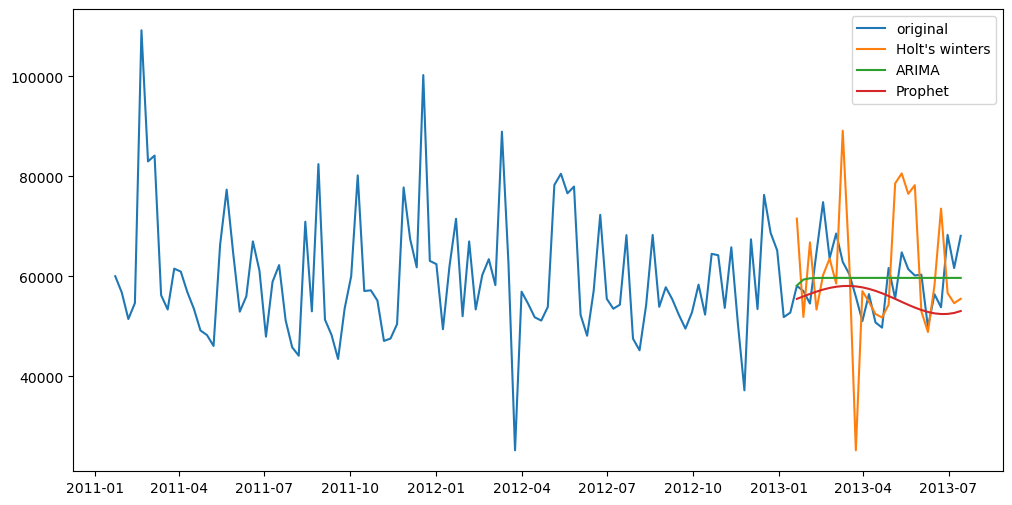

The best model is: ARIMA


In [29]:
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet

data = pd.read_csv(r'data/demand.csv')

data['week'] = pd.to_datetime(data['week'], format='%d/%m/%y')
data.set_index('week', inplace=True)

# Aggreate the data to weekly frquency
weekly_data = data['units_sold'].resample('W').sum()

train_data = weekly_data[:int(0.8*len(weekly_data))]
test_data = weekly_data[int(0.8*len(weekly_data)):]

# Fit a Holt-Winters model
hw_model = ExponentialSmoothing(train_data, seasonal='add', seasonal_periods=52).fit()

# Generate predictions from the Holt-Winters model
hw_predictions = hw_model.predict(start=test_data.index[0], end=test_data.index[-1])

# Fit an ARIMA model
arima_model = ARIMA(train_data, order=(1, 0, 0)).fit()

# Generate predictions from the ARIMA model
predictions_arima = arima_model.predict(start=test_data.index[0], end=test_data.index[-1])

# Fit a Prophet model
prophet_data = weekly_data.reset_index()
prophet_data.columns = ['ds', 'y']

prophet_train_data = prophet_data[:int(0.8*len(prophet_data))]
prophet_test_data = prophet_data[int(0.8*len(prophet_data)):]

prophet_model = Prophet(yearly_seasonality=True).fit(prophet_train_data)

# generate predictions from the Prophet model
prophet_future = prophet_model.make_future_dataframe(periods = len(prophet_test_data))
prophet_forecast = prophet_model.predict(prophet_future)

# Calculate the RMSE for each model
hw_rmse = sqrt(mean_squared_error(test_data, hw_predictions))
arima_rmse = sqrt(mean_squared_error(test_data, predictions_arima))
prophet_rmse = sqrt(mean_squared_error(prophet_test_data['y'], prophet_forecast['yhat'][-len(prophet_test_data):]))

# Print the RMSE for each model
print(f'Holt-Winters RMSE: {hw_rmse}')
print(f'ARIMA RMSE: {arima_rmse}')
print(f'Prophet RMSE: {prophet_rmse}')

# plot the actual vs predicted values for each model
plt.figure(figsize=(12, 6))
plt.plot(weekly_data, label='original')
plt.plot(hw_predictions, label="Holt's winters")
plt.plot(predictions_arima, label='ARIMA')
plt.plot(test_data.index, prophet_forecast['yhat'][-len(prophet_test_data):].values, label='Prophet')
plt.legend()
plt.show()

# Compare the models and print the name of the best model
rmse_values = [hw_rmse, arima_rmse, prophet_rmse]
model_names = ['Holt-Winters', 'ARIMA', 'Prophet']
best_model = model_names[rmse_values.index(min(rmse_values))]

print(f'The best model is: {best_model}')

In [30]:
df = data

# Aggregate the data by week
weekly_data_fb = df['units_sold'].resample('W').sum()

# Prepare the data for Prophet
fbprophet_data = weekly_data_fb.reset_index()
fbprophet_data.columns = ['ds', 'y']

In [31]:
# Split the data into train and test sets
train_data_prophet = fbprophet_data[:int(0.8*(len(fbprophet_data)))]
test_data_prophet = fbprophet_data[int(0.8*(len(fbprophet_data))):]

In [32]:
import matplotlib.pyplot as plt
import numpy as np
# Fit a Prophet model
prophet_model = Prophet(yearly_seasonality=True)
prophet_model.fit(train_data_prophet)

# Generate predictions from the Prophet model for the test period
prophet_future = prophet_model.make_future_dataframe(periods=len(test_data_prophet))
prophet_predictions = prophet_model.predict(prophet_future)

# Extract the predicted and actual values
prophet_predicted = prophet_predictions[-len(test_data_prophet):]['yhat']
prophet_actual = test_data_prophet['y']

# Calculate the RMSE
prophet_rmse = np.sqrt(mean_squared_error(prophet_actual, prophet_predicted))
print('Prophet RMSE:', prophet_rmse)


Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
16:13:25 - cmdstanpy - INFO - Chain [1] start processing
16:13:25 - cmdstanpy - INFO - Chain [1] done processing


Prophet RMSE: 7717.694626470364


In [ ]:
final_df=pd.DataFrame(prophet_predictions)

import plotly.graph_objs as go
import plotly.offline as py

#Plot predicted and actual line graph with X=dates, Y=Outbound
actual_chart = go.Scatter(y=train_data_prophet["y"], name= 'Actual')
predict_chart = go.Scatter(y=final_df["yhat"], name= 'Predicted')
predict_chart_upper = go.Scatter(y=final_df["yhat_upper"], name= 'Predicted Upper')
predict_chart_lower = go.Scatter(y=final_df["yhat_lower"], name= 'Predicted Lower')
py.plot([actual_chart, predict_chart, predict_chart_upper, predict_chart_lower])

'temp-plot.html'

In [36]:
import plotly.graph_objs as go
import plotly.offline as py

final_df = pd.DataFrame(prophet_predictions)

actual_chart = go.Scatter(
    x=test_data_prophet['ds'],
    y=test_data_prophet['y'],
    mode='lines',
    name='Actual'
)

predict_chart = go.Scatter(
    x=test_data_prophet['ds'],
    y=final_df['yhat'].tail(len(test_data_prophet)),
    mode='lines',
    name='Predicted'
)

upper_chart = go.Scatter(
    x=test_data_prophet['ds'],
    y=final_df['yhat_upper'].tail(len(test_data_prophet)),
    mode='lines',
    name='Upper Bound'
)

lower_chart = go.Scatter(
    x=test_data_prophet['ds'],
    y=final_df['yhat_lower'].tail(len(test_data_prophet)),
    mode='lines',
    name='Lower Bound'
)

py.plot([actual_chart, predict_chart, upper_chart, lower_chart])

'temp-plot.html'